In [1]:
pip install scikit-learn

  Using cached joblib-1.4.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached threadpoolctl-3.5.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB 393.8 kB/s eta 0:00:28
   ---------------------------------------- 0.1/10.9 MB 737.3 kB/s eta 0:00:15
    --------------------------------------- 0.2/10.9 MB 1.3 MB/s eta 0:00:09
   - -------------------------------------- 0.4/10.9 MB 1.7 MB/s eta 0:00:07
   - -------------------------------------- 0.5/10.9 MB 1.9 MB/s eta 0:00:06
   -- ------------------------------------- 0.6/10.9 MB 1.9 MB/s eta 0:00:06
   -- ------------------------------------- 0.7/10.9 MB 2.0 MB/s eta 0:00:06
   --- ------------------------------------ 0.8/10.9 MB 2.0 MB/s eta 0:00:06
   --- -------------------------------

# Introduction to Scikit-Learn (sklearn)

This notebook demonstrate some of the most useful functions of the beautiful Scikit-Learn library.

What we're going to cover:

0. An end-to-end Scikit-Learn workflow
1. Getting the data ready
2. Choose the right estimator/algorithm for our problems
3. Fit the model/algorithm and use it to make predictions on our data
4. Evaluation a model
5. Improve a model
6. Save and load a trained model
7. Putting it all together!

## 0. An end-to-end Scikit-Learn workflow

In [2]:
# 1. An end-to-end Scikit-Learn workflow
import pandas as pd
import numpy as np
heart_disease = pd.read_csv("heart-disease.csv")
heart_disease

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [3]:
import warnings
warnings.filterwarnings('ignore')
# warnings.filterwarnings("default")

In [4]:
import sklearn
sklearn.show_versions()


System:
    python: 3.12.3 | packaged by Anaconda, Inc. | (main, Apr 19 2024, 16:41:55) [MSC v.1916 64 bit (AMD64)]
executable: C:\Users\Admin\anaconda3\envs\myenv\python.exe
   machine: Windows-10-10.0.19045-SP0

Python dependencies:
      sklearn: 1.5.1
          pip: 23.3.1
   setuptools: 68.2.2
        numpy: 1.26.4
        scipy: 1.13.1
       Cython: None
       pandas: 2.2.2
   matplotlib: 3.8.4
       joblib: 1.4.2
threadpoolctl: 3.5.0

Built with OpenMP: True

threadpoolctl info:
       user_api: blas
   internal_api: openblas
    num_threads: 4
         prefix: libopenblas
       filepath: C:\Users\Admin\anaconda3\envs\myenv\Lib\site-packages\numpy.libs\libopenblas64__v0.3.23-293-gc2f4bdbb-gcc_10_3_0-2bde3a66a51006b2b53eb373ff767a3f.dll
        version: 0.3.23.dev
threading_layer: pthreads
   architecture: Haswell

       user_api: openmp
   internal_api: openmp
    num_threads: 4
         prefix: vcomp
       filepath: C:\Users\Admin\anaconda3\envs\myenv\Lib\site-packages\s

In [5]:
# Create X (Feature matrix)
X = heart_disease.drop("target",axis=1)
# Create y (labels)
y = heart_disease["target"]

In [6]:
# Choose the right model and hyperprameters
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier()

#we'll keep the default hyperparameters
clf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [7]:
# 3. Fit the model to the training data
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.2)

In [8]:
clf.fit(X_train,y_train);

In [9]:
# make a prediction
# y_label = clf.predict(np.array([0,2,3,4]))
y_preds = clf.predict(X_test)
y_preds

array([1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1,
       0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1], dtype=int64)

In [10]:
y_test

143    1
275    0
113    1
160    1
236    0
      ..
224    0
199    0
300    0
45     1
151    1
Name: target, Length: 61, dtype: int64

In [11]:
# Evaluate the model on the training data and test data
clf.score(X_train,y_train)

1.0

In [12]:
clf.score(X_test,y_test)

0.8688524590163934

In [13]:
from sklearn.metrics import classification_report , confusion_matrix ,accuracy_score

print(classification_report(y_test,y_preds))

              precision    recall  f1-score   support

           0       0.89      0.83      0.86        30
           1       0.85      0.90      0.88        31

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



In [14]:
confusion_matrix(y_test, y_preds)

array([[25,  5],
       [ 3, 28]], dtype=int64)

In [15]:
accuracy_score(y_test, y_preds)

0.8688524590163934

In [16]:
# 5. Improve a model
# Try different amount of n_estimators
np.random.seed(42)
for i in range(10,100,10):
    print(f"Trying model with {i} estimators...")
    clf = RandomForestClassifier(n_estimators = i).fit(X_train,y_train)
    print(f"Model accuracy on the test set: {clf.score(X_test,y_test) * 100:.2f}%")
    print("")

Trying model with 10 estimators...
Model accuracy on the test set: 86.89%

Trying model with 20 estimators...
Model accuracy on the test set: 86.89%

Trying model with 30 estimators...
Model accuracy on the test set: 80.33%

Trying model with 40 estimators...
Model accuracy on the test set: 86.89%

Trying model with 50 estimators...
Model accuracy on the test set: 80.33%

Trying model with 60 estimators...
Model accuracy on the test set: 86.89%

Trying model with 70 estimators...
Model accuracy on the test set: 90.16%

Trying model with 80 estimators...
Model accuracy on the test set: 90.16%

Trying model with 90 estimators...
Model accuracy on the test set: 90.16%



In [17]:
import pickle
pickle.dump(clf, open("random_forest_model_1.pkl","wb")) 

In [18]:
loaded_model = pickle.load(open("random_forest_model_1.pkl","rb"))
loaded_model.score(X_test,y_test)

0.9016393442622951

In [19]:
what_were_covering = ["0. An end-to-end Scikit-Learn workflow",
"1. Getting the data ready"
,"2. Choose the right estimator/algorithm for our problems"
,"3. Fit the model/algorithm and use it to make predictions on our data"
,"4. Evaluation a model"
,"5. Improve a model"
,"6. Save and load a trained model"
,"7. Putting it all together!"]

In [20]:
what_were_covering

['0. An end-to-end Scikit-Learn workflow',
 '1. Getting the data ready',
 '2. Choose the right estimator/algorithm for our problems',
 '3. Fit the model/algorithm and use it to make predictions on our data',
 '4. Evaluation a model',
 '5. Improve a model',
 '6. Save and load a trained model',
 '7. Putting it all together!']

In [21]:
#standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Getting our data ready to be used with machine learning

Three main things we have to do:

    1. Split the data into features and labels (usally "X" & "Y")
    2. Filling (also called imputing) or disregarding missing values
    3. Converting non-numerical values to numerical values(also callled feature encoding)

In [22]:
X = heart_disease.drop("target", axis=1)
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


In [23]:
y = heart_disease["target"]
y.head()

0    1
1    1
2    1
3    1
4    1
Name: target, dtype: int64

In [24]:
#Split the data into training and test sets
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

In [25]:
X_train.shape,X_test.shape, y_test.shape,y_train.shape

((242, 13), (61, 13), (61,), (242,))

## 1.1 Make sure it's all numerical

In [26]:
car_sales = pd.read_csv("car-sales-extended.csv")

In [27]:
car_sales.head()

,Make,Colour,Odometer (KM),Doors,Price
0,Honda,White,35431,4,15323
1,BMW,Blue,192714,5,19943
2,Honda,White,84714,4,28343
3,Toyota,White,154365,4,13434
4,Nissan,Blue,181577,3,14043


In [28]:
car_sales.dtypes

Make             object
Colour           object
Odometer (KM)     int64
Doors             int64
Price             int64
dtype: object

In [29]:
#split into X/y
X = car_sales.drop("Price", axis=1)
y = car_sales["Price"]

#Split into training and test
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2)

In [30]:
# Build ML model
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor()
# model.fit(X_train,y_train)
# model.score()

In [31]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorial_features = ['Make',"Colour", "Doors"]
one_hot = OneHotEncoder()
transformer = ColumnTransformer([("one_hot",one_hot,categorial_features)],remainder = 'passthrough')
transformed_X = transformer.fit_transform(X)
transformed_X

array([[0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        0.00000e+00, 3.54310e+04],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        1.00000e+00, 1.92714e+05],
       [0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        0.00000e+00, 8.47140e+04],
       ...,
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 1.00000e+00,
        0.00000e+00, 6.66040e+04],
       [0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        0.00000e+00, 2.15883e+05],
       [0.00000e+00, 0.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        0.00000e+00, 2.48360e+05]])

In [32]:
X.head()

,Make,Colour,Odometer (KM),Doors
0,Honda,White,35431,4
1,BMW,Blue,192714,5
2,Honda,White,84714,4
3,Toyota,White,154365,4
4,Nissan,Blue,181577,3


In [33]:
pd.DataFrame(transformed_X)

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,35431.0
1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,192714.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,84714.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,154365.0
4,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,181577.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,35820.0
996,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,155144.0
997,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,66604.0
998,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,215883.0


In [34]:
X['Make'].value_counts()

Make
Toyota    398
Honda     304
Nissan    198
BMW       100
Name: count, dtype: int64

In [35]:
dummies = pd.get_dummies(car_sales[["Make",'Colour','Doors']],dtype=int)
dummies

,Doors,Make_BMW,Make_Honda,Make_Nissan,Make_Toyota,Colour_Black,Colour_Blue,Colour_Green,Colour_Red,Colour_White
0,4,0,1,0,0,0,0,0,0,1
1,5,1,0,0,0,0,1,0,0,0
2,4,0,1,0,0,0,0,0,0,1
3,4,0,0,0,1,0,0,0,0,1
4,3,0,0,1,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...
995,4,0,0,0,1,1,0,0,0,0
996,3,0,0,1,0,0,0,0,0,1
997,4,0,0,1,0,0,1,0,0,0
998,4,0,1,0,0,0,0,0,0,1


In [36]:
np.random.seed(42)
X_train, X_test, y_train,y_test = train_test_split(transformed_X,y, test_size=0.2)

In [37]:
model.fit(X_train,y_train);

In [38]:
model.score(X_test,y_test)

0.3235867221569877

In [39]:
print(sklearn.__version__)

1.5.1


In [40]:
# class person:
#     def __init__(self,name='Haseeb',height=176,colour='black'):
#         self.name = name
#         self.height = height
#         self.hair_colour = colour
#     def height_in_inches(self):
#         inches = self.height/2.54
#         return inches


# class school(person):
#     def __init__(self,school_name,class_name,name,height=176,colour='black'):
#         super().__init__(name,height,colour)
#         self.school_name = school_name
#         self.class_name = class_name
#         self.height = self.height_in_inches()
#     def addmission(self):
#         return f'{self.name.title()} you got admission in {self.school_name}, in class {self.class_name}, You got {self.hair_colour} hairs and your height is {self.height:.2f} inches'
        

# peson_instance = person()
# x = peson_instance.height_in_inches()
# x
# school_instance = school('BGS','8th',"haseeb")
# y = school_instance.addmission()
# y

### 1.2 What if there were missing values?

1. Fill them some value (also known as imputation).
2. Remove the samples with missing data altogether.

In [41]:
# import car sales missing data
car_sales_missing = pd.read_csv("car-sales-extended-missing-data.csv")
car_sales_missing.head()

,Make,Colour,Odometer (KM),Doors,Price
0,Honda,White,35431.0,4.0,15323.0
1,BMW,Blue,192714.0,5.0,19943.0
2,Honda,White,84714.0,4.0,28343.0
3,Toyota,White,154365.0,4.0,13434.0
4,Nissan,Blue,181577.0,3.0,14043.0


In [42]:
car_sales_missing.isna().sum()

Make             49
Colour           50
Odometer (KM)    50
Doors            50
Price            50
dtype: int64

In [43]:
# Create X nad y
X = car_sales_missing.drop("Price", axis=1)
y = car_sales_missing["Price"]

In [44]:
#lets try and convert our data inito numbers
# Turn the categories into numbers
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_feature = ["Male","Colour","Door"]
one_hot = OneHotEncoder()
transformer = ColumnTransformer([("one_hot",one_hot,categorial_features)],remainder="passthrough")

transformed_X = transformer.fit_transform(X)
transformed_X

<1000x16 sparse matrix of type '<class 'numpy.float64'>'
	with 4000 stored elements in Compressed Sparse Row format>

### Option 1: Fill missing data with pandas

In [45]:
# Fill the "Make" column
car_sales_missing["Make"].fillna("missing", inplace = True)

# Fill the "Colour" column
car_sales_missing['Colour'].fillna('missing', inplace = True)

# Fill the "Odometer (KM)" column
car_sales_missing['Odometer (KM)'].fillna(car_sales_missing['Odometer (KM)'].mean(), inplace=True)

# Fill the "Doors" column
car_sales_missing['Doors'].fillna(4, inplace = True)

In [46]:
car_sales_missing.isna().sum()

Make              0
Colour            0
Odometer (KM)     0
Doors             0
Price            50
dtype: int64

In [47]:
# remove rows with missing Price value
car_sales_missing.dropna(inplace=True)

In [48]:
car_sales_missing.isna().sum()

Make             0
Colour           0
Odometer (KM)    0
Doors            0
Price            0
dtype: int64

In [49]:
car_sales_missing['Doors'].value_counts()

Doors
4.0    815
5.0     71
3.0     64
Name: count, dtype: int64

In [50]:
X = car_sales_missing.drop('Price',axis=1)
y = car_sales_missing['Price']

In [51]:
#lets try and convert our data inito numbers
# Turn the categories into numbers
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_feature = ["Male","Colour","Door"]
one_hot = OneHotEncoder()
transformer = ColumnTransformer([("one_hot",one_hot,categorial_features)],remainder="passthrough")

transformed_X = transformer.fit_transform(X)
transformed_X

<950x15 sparse matrix of type '<class 'numpy.float64'>'
	with 3800 stored elements in Compressed Sparse Row format>

### Option 2: Fill missing values with Scikit-Learn

1.Feature Scaling with scikit-learn
    In this post we explore 3 methods of feature scaling that are implemented in scikit-learn:

    StandardScaler
    MinMaxScaler
    RobustScaler
    Normalizer


    Standard Scaler
        The StandardScaler assumes your data is normally distributed within each feature and will scale them such that the distribution is now centred around 0, with a standard deviation of 1.
        
        The mean and standard deviation are calculated for the feature and then the feature is scaled based on:
        
        xi–mean(x)/stdev(x)
        If data is not normally distributed, this is not the best scaler to use.


    Min-Max Scaler
        The MinMaxScaler is the probably the most famous scaling algorithm, and follows the following formula for each feature:
        
        xi–min(x)/max(x)–min(x)
        It essentially shrinks the range such that the range is now between 0 and 1 (or -1 to 1 if there are negative values).
        
        This scaler works better for cases in which the standard scaler might not work so well. If the distribution is not Gaussian or the standard deviation is very small, the min-max scaler works better.
        
        However, it is sensitive to outliers, so if there are outliers in the data, you might want to consider the Robust Scaler below.

    Robust Scaler
        The RobustScaler uses a similar method to the Min-Max scaler but it instead uses the interquartile range, rathar than the min-max, so that it is robust to outliers. Therefore it follows the formula:
        
        xi–Q1(x)/Q3(x)–Q1(x)
        For each feature.
        
        Of course this means it is using the less of the data for scaling so it’s more suitable for when there are outliers in the data.

    Normalizer
        The normalizer scales each value by dividing each value by its magnitude in n
        -dimensional space for n
         number of features.
        
        Say your features were x, y and z Cartesian co-ordinates your scaled value for x would be:
        
        xi/√x**2i+y**2i+z**2i
        Each point is now within 1 unit of the origin on this Cartesian co-ordinate system.

In [52]:
car_sales_missing = pd.read_csv("car-sales-extended-missing-data.csv")
car_sales_missing.head()

,Make,Colour,Odometer (KM),Doors,Price
0,Honda,White,35431.0,4.0,15323.0
1,BMW,Blue,192714.0,5.0,19943.0
2,Honda,White,84714.0,4.0,28343.0
3,Toyota,White,154365.0,4.0,13434.0
4,Nissan,Blue,181577.0,3.0,14043.0


In [53]:
car_sales_missing.isna().sum()

Make             49
Colour           50
Odometer (KM)    50
Doors            50
Price            50
dtype: int64

In [54]:
car_sales_missing.dropna(subset = ["Price"], inplace=True)

In [55]:
car_sales_missing.isna().sum()

Make             47
Colour           46
Odometer (KM)    48
Doors            47
Price             0
dtype: int64

In [56]:
#split into X & y
X = car_sales_missing.drop('Price',axis=1)
y = car_sales_missing['Price']

In [57]:
# Fill missing values with Scikit-Learn
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

# fill categorical values with "Missing" & numerical values with mean
cat_imputer = SimpleImputer(strategy='constant',fill_value='missing')
door_imputer = SimpleImputer(strategy='constant', fill_value=4)
num_imputer = SimpleImputer(strategy='mean')

# Define columns
cat_features = ['Make', 'Colour']
door_feature = ['Doors']
num_feature = ['Odometer (KM)']

# Create and imputer (Something that fills missing data)
imputer = ColumnTransformer([('cat_imputer', cat_imputer,cat_features),
                            ('door_imputer',door_imputer,door_feature),
                            ('num_feature', num_imputer,num_feature)])
# Transform the data
filled_X = imputer.fit_transform(X)
filled_X

array([['Honda', 'White', 4.0, 35431.0],
       ['BMW', 'Blue', 5.0, 192714.0],
       ['Honda', 'White', 4.0, 84714.0],
       ...,
       ['Nissan', 'Blue', 4.0, 66604.0],
       ['Honda', 'White', 4.0, 215883.0],
       ['Toyota', 'Blue', 4.0, 248360.0]], dtype=object)

In [58]:
# filled_X= pd.DataFrame(filled_X)    #testing

In [59]:
# filled_X.isna().sum()   #testing

In [60]:
car_sales_filled = pd.DataFrame(filled_X, columns=['Make','Colour','Doors','Odometer (KM)'])

In [61]:
car_sales_filled.head()

,Make,Colour,Doors,Odometer (KM)
0,Honda,White,4.0,35431.0
1,BMW,Blue,5.0,192714.0
2,Honda,White,4.0,84714.0
3,Toyota,White,4.0,154365.0
4,Nissan,Blue,3.0,181577.0


In [62]:
# Lets try and convert our data into numbers
# Turns the categories into numbers
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_features = ['Make','Colour','Doors']
one_hot = OneHotEncoder()
transformer = ColumnTransformer([('one_hot',one_hot,categorical_features)],
                               remainder='passthrough')

transformed_X = transformer.fit_transform(car_sales_filled)
transformed_X

<950x15 sparse matrix of type '<class 'numpy.float64'>'
	with 3800 stored elements in Compressed Sparse Row format>

In [63]:
# Now we got our data as number and filled (no missing values)
# let's fit a model
np.random.seed(42)
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(transformed_X,y,test_size=0.2)

model = RandomForestRegressor()
model.fit(X_train,y_train)
model.score(X_test,y_test)

0.21990196728583944

In [64]:
len(car_sales_filled), len(car_sales)

(950, 1000)

## 2. Choosing the right estimator/algorithm for your problem

### 2.1 Picking a ML model for a regression problem

In [65]:
# Get California Housing dataset
from sklearn.datasets import fetch_california_housing
housing =  fetch_california_housing()
housing

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]]),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894]),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': '.. _california_housing_dataset:\n

In [66]:
housing_df = pd.DataFrame(housing['data'], columns=housing['feature_names'])
housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [67]:
housing_df['target'] = housing['target']

In [68]:
# housing_df = housing_df.drop('MedHouseVal',axis=1)

In [69]:
housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [70]:
# import alogorithm/estimator
from sklearn.linear_model import Ridge

#setup random seed
np.random.seed(42)

# Create the data
X = housing_df.drop('target', axis=1)
y = housing_df['target']  # median house price in $100,000s

# Split into train and test sets
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

# Instantiate and fit the model (on the training set)
model = Ridge()
model.fit(X_train,y_train)


#check the score of the model (on the set)
model.score(X_test,y_test)

0.5758549611440127

What if `Ridge` didn't work or the score didn't fit our needs?

Well, we could always try a different model...

How about we try an ensamble model (an ensamble is combination of samller models to try and make better prediction than just a single model)?

Sklearn's ensamble models can be found here: https://scikit-learn.org/stable/modules/ensemble.html

In [71]:
# import the randomForestRegressor model calss from the ensemble module
from sklearn.ensemble import RandomForestClassifier

np.random.seed(42)

X = housing_df.drop('target',axis=1)
y = housing_df['target']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

model = RandomForestRegressor()
model.fit(X_train,y_train)

model.score(X_test,y_test)

0.8065734772187598

## 2.2 Picking a machine learning model for a classification problem

In [72]:
heart_disease = pd.read_csv('heart-disease.csv')
heart_disease.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [73]:
#import the linearSVC estimator class
from sklearn.svm import LinearSVC

#setup random seed
np.random.seed(42)

#make the data
X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

#split the data

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#initiate LinearSVC
clf = LinearSVC(max_iter = 10000)
clf.fit(X_train,y_train)

# Evaluate the linearSVC
clf.score(X_test,y_test)

0.8688524590163934

In [74]:
#import the RandomForestClassifier estimator class
from sklearn.ensemble import RandomForestClassifier

#setup random seed
np.random.seed(42)

#make the data
X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

#split the data

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#initiate RandomForestClassifier
clf = RandomForestClassifier()
clf.fit(X_train,y_train)

# Evaluate the RandomForestClassifier
clf.score(X_test,y_test)

0.8524590163934426

### Tidbit:

    1. If you have structured data , used ensemble methods
    2. If you have unstructured data, use deep-learning or transfer learning

## 3. Fit the model/algorithm on our data and use it to make predictions

### 3.1 Fitting the model to the data

* `X` = features, features variables, data
* `y` = labels, target, target variables

In [75]:
#import the RandomForestClassifier estimator class
from sklearn.ensemble import RandomForestClassifier

#setup random seed
np.random.seed(42)

#make the data
X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

#split the data

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#initiate RandomForestClassifier
clf = RandomForestClassifier(n_estimators=100)

#Fit the model to the data
clf.fit(X_train,y_train)

# Evaluate the RandomForestClassifier
clf.score(X_test,y_test)

0.8524590163934426

### 3.2 Make a prediction using a machine learning model

2 ways to make predictions:
* 1. `predict()`
* 2. `predict_proba()`

In [76]:
# Use a trained model to make predictions
clf.predict(X_test)

array([0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0], dtype=int64)

In [77]:
np.array(y_test)

array([0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0], dtype=int64)

In [78]:
# Compare predictions to truth lables to evaluate model
y_preds = clf.predict(X_test)
np.mean(y_preds == y_test)

0.8524590163934426

In [79]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_preds)

0.8524590163934426

### Make predictions with `predict_proba()`


In [80]:
clf.predict_proba(X_test[:5])

array([[0.89, 0.11],
       [0.49, 0.51],
       [0.43, 0.57],
       [0.84, 0.16],
       [0.18, 0.82]])

In [81]:
# lets predict() on the same data...
clf.predict(X_test[:5])

array([0, 1, 1, 0, 1], dtype=int64)

`predict()` can also be used for regression models

In [82]:
housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [83]:
from sklearn.ensemble import RandomForestRegressor
np.random.seed(42)

# create the data
X = housing_df.drop('target',axis=1)
y = housing_df['target']

# split into training and test data sets
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#create model instance
model = RandomForestRegressor()

# fit the model to the data
model.fit(X_train, y_train)

# Make predictions
y_preds = model.predict(X_test)

In [84]:
y_preds[:10]

array([0.49384  , 0.75494  , 4.9285964, 2.54316  , 2.33176  , 1.6525301,
       2.34323  , 1.66182  , 2.47489  , 4.8344779])

In [85]:
np.array(y_test[:10])

array([0.477  , 0.458  , 5.00001, 2.186  , 2.78   , 1.587  , 1.982  ,
       1.575  , 3.4    , 4.466  ])

In [86]:
# compare the predictions to the truth
from sklearn.metrics import mean_absolute_error
mean_absolute_error(y_test,y_preds)

0.32659871732073664

In [87]:
housing_df['target']

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: target, Length: 20640, dtype: float64

## 4. Evaluating a machine learning model

Three ways to evaluate Scikit_learn models/estimators:
1. Estimator's built-in `score()` method
2. the `scoring` parameter
3. Problem-specific metric functions

### 4.1 Evaluating a model with the `score` mehtod

In [88]:
from sklearn.ensemble import RandomForestClassifier
np.random.seed(42)
X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

clf = RandomForestClassifier(n_estimators=1000)
clf.fit(X_train,y_train)

RandomForestClassifier(n_estimators=1000)

In [89]:
clf.score(X_test,y_test)

0.8688524590163934

Lets use the `score()` on our regression problem

In [90]:
from sklearn.ensemble import RandomForestRegressor
np.random.seed(42)

# create the data
X = housing_df.drop('target',axis=1)
y = housing_df['target']

# split into training and test data sets
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#create model instance
model = RandomForestRegressor(n_estimators=100)

# fit the model to the data
model.fit(X_train, y_train)

# Make predictions
# y_preds = model.predict(X_test)

RandomForestRegressor()

In [91]:
# The default score() evaluation metric is r_squared for regression algorithms
# Highest = 1.0, lowest = 0.0
model.score(X_test,y_test)

0.8065734772187598

# 4.2 Evaluating a model using the `scoring` parameter

In [92]:
from sklearn.model_selection import cross_val_score

#import the RandomForestClassifier estimator class
from sklearn.ensemble import RandomForestClassifier

#setup random seed
np.random.seed(42)

#make the data
X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

#split the data

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#initiate RandomForestClassifier
clf = RandomForestClassifier(n_estimators=100)

#Fit the model to the data
clf.fit(X_train,y_train)

# Evaluate the RandomForestClassifier
clf.score(X_test,y_test)

0.8524590163934426

In [93]:
# Cross-Validation
cross_val_score(clf,X,y,cv=5)

array([0.81967213, 0.86885246, 0.81967213, 0.78333333, 0.76666667])

In [94]:
np.random.seed(42)

#single training and test split score
clf_single_score = clf.score(X_test, y_test)

# Take the mran of 5-fold cross-validation score
clf_cross_val_score = np.mean(cross_val_score(clf,X,y,cv=5))

# Compare the two
clf_single_score , clf_cross_val_score

(0.8524590163934426, 0.8248087431693989)

In [95]:
# Default scoring parameter of classifier = mean accuracy
clf.score()

TypeError: ClassifierMixin.score() missing 2 required positional arguments: 'X' and 'y'

In [96]:
# Scoring parameter set to None by default
cross_val_score(clf,X,y,cv=5,scoring=None)


array([0.78688525, 0.86885246, 0.80327869, 0.78333333, 0.76666667])

### 4.2.1 Classification model evaluation metrics

1. Accuracy
2. Are under ROC curve
3. Confusion matrix
4. Classification report

**Accuracy**

In [97]:
heart_disease.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [98]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

np.random.seed(42)

X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

# X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.2)

clf = RandomForestClassifier(n_estimators=100)
cross_val_score = cross_val_score(clf,X,y,cv=5)

In [99]:
np.mean(cross_val_score)

0.8248087431693989

In [100]:
print(f"Heart Disease Classifier Cross-Validated Accuracy: {np.mean(cross_val_score) * 100:.2f}%")

Heart Disease Classifier Cross-Validated Accuracy: 82.48%


**Area under the receiver operating characteristic curve (AUC/ROC)**
* Area under curve (AUC)
* ROC curve

ROC curves are a comparison of a model's true positve rate (tpr) versus a  models false positive rate (fpr).

* True positive = model predicts 1 when truth is 1
* False positive = model predicts 1 when truth is 0
* True negative = model predicts 0 when truth is 0
* False negative =  model predicts 0 when truth is 1

In [101]:
from sklearn.metrics import roc_curve
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)
# Mkae predictions with probabilities
clf.fit(X_train,y_train)
y_probs = clf.predict_proba(X_test)

y_probs[:10], len(y_probs)

(array([[0.51, 0.49],
        [0.17, 0.83],
        [0.51, 0.49],
        [0.72, 0.28],
        [0.43, 0.57],
        [0.12, 0.88],
        [0.3 , 0.7 ],
        [0.97, 0.03],
        [0.15, 0.85],
        [0.4 , 0.6 ]]),
 61)

In [102]:
y_probs_positives = y_probs[:,1]
y_probs_positives[:10]

array([0.49, 0.83, 0.49, 0.28, 0.57, 0.88, 0.7 , 0.03, 0.85, 0.6 ])

In [103]:
# calculate fpr, tpr and thresholds
fpr,tpr, thresholds = roc_curve(y_test,y_probs_positives)

# check the false positive rates
fpr

array([0.        , 0.03448276, 0.03448276, 0.03448276, 0.03448276,
       0.03448276, 0.03448276, 0.06896552, 0.06896552, 0.06896552,
       0.10344828, 0.10344828, 0.13793103, 0.13793103, 0.13793103,
       0.20689655, 0.20689655, 0.20689655, 0.27586207, 0.37931034,
       0.37931034, 0.48275862, 0.48275862, 0.55172414, 0.55172414,
       1.        ])

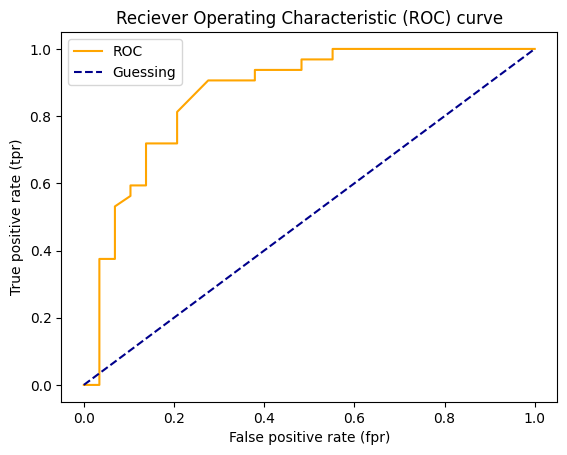

In [104]:
# Create a function fro plotting ROC curves
import matplotlib.pyplot as plt

def plot_roc_curve(fpr,tpr):
    """
    Plots a ROC curve given the fpr and tpr of a model.
    """
    # plot roc curve
    plt.plot(fpr,tpr,color="orange", label='ROC')
    # Plot line with no predictive power (baseline)
    plt.plot([0,1],[0,1], color = 'darkblue', linestyle='--', label="Guessing")

    # Customze the plot
    plt.xlabel('False positive rate (fpr)')
    plt.ylabel('True positive rate (tpr)')
    plt.title("Reciever Operating Characteristic (ROC) curve")
    plt.legend()
    plt.show()

plot_roc_curve(fpr,tpr)

In [105]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_test, y_probs_positives)

0.8669181034482759

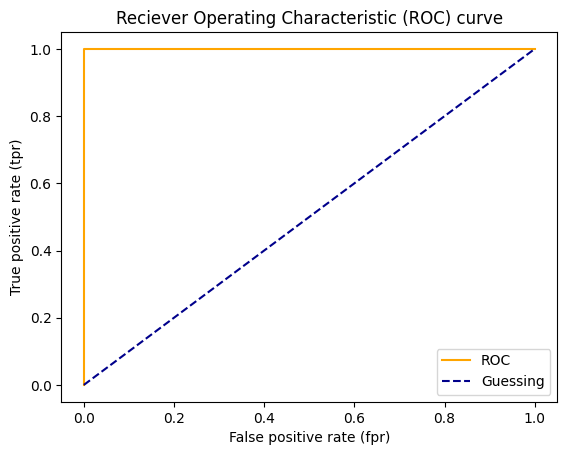

In [106]:
# plot perfect ROC curve and AUC score
fpr,tpr,thresholds = roc_curve(y_test,y_test)
plot_roc_curve(fpr,tpr)

In [107]:
# perfect AUC score
roc_auc_score(y_test,y_test)

1.0

**Confusion Matrix**

A confusion matrix is a quick way to compare the labels a model predicts and the actual labels it was supposed t predict.

In Essence, giving you an idea of where the model is getting confused.

**NEW**

The next way to evaluate a classification model is by using confusion matrix.

A confusion matrix is a quick way to compare the labels a model predicts and the actual labels it was supposed to predicts and the actual label it was supposed to predict.

In essence, this gives you an idea of where the model is getting confused.

In [108]:
from sklearn.metrics import confusion_matrix
y_preds = clf.predict(X_test)

confusion_matrix(y_test,y_preds)

array([[23,  6],
       [ 6, 26]], dtype=int64)

In [109]:
# Visualize confusion matrix with pd.crosstab()

pd.crosstab(y_test,y_preds,rownames=['Actual Labels'],
           colnames=["Predicted Labels"])

Predicted Labels,0,1
Actual Labels,,
0,23,6
1,6,26


In [110]:
len(y_preds)

61

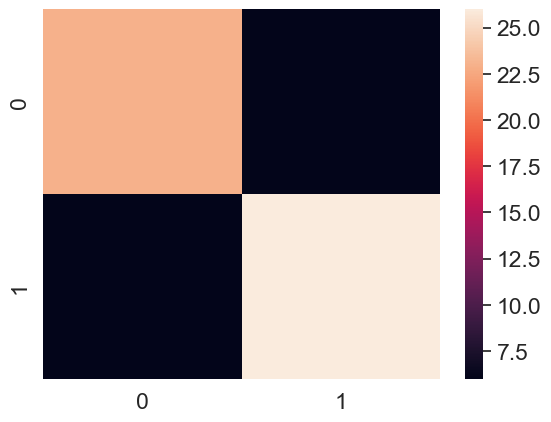

In [111]:
# Make our confusion matrix more visual with Seaborn's heatmap()
import seaborn as sns

sns.set(font_scale=1.5)

conf_mat = confusion_matrix(y_test,y_preds)

sns.heatmap(conf_mat);

**NEW starts from here**

In [112]:
from sklearn.metrics import confusion_matrix
y_preds = clf.predict(X_test)

confusion_matrix(y_test,y_preds)

array([[23,  6],
       [ 6, 26]], dtype=int64)

In [113]:
pd.crosstab(y_test,y_preds,rownames=['Actual Label'], colnames=['Predicted Label'])

Predicted Label,0,1
Actual Label,,
0,23,6
1,6,26


### Creating a counfusion matrix using scikit-learn

To use the new methods of creating a counfusion matrix with scikit-learn you will need sklearn version 1.0+

In [114]:
import sklearn
sklearn.__version__

'1.5.1'

In [115]:
clf

RandomForestClassifier()

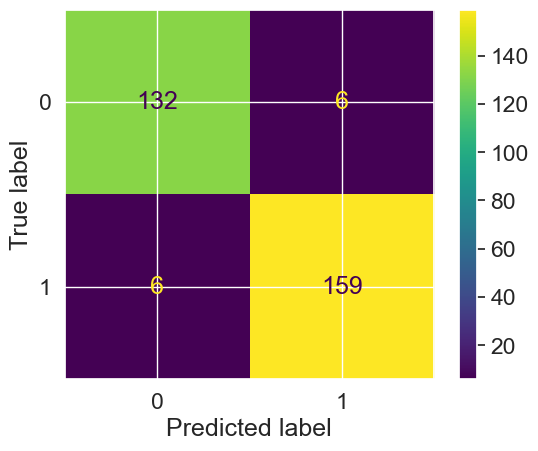

In [116]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(estimator=clf, X=X, y=y)

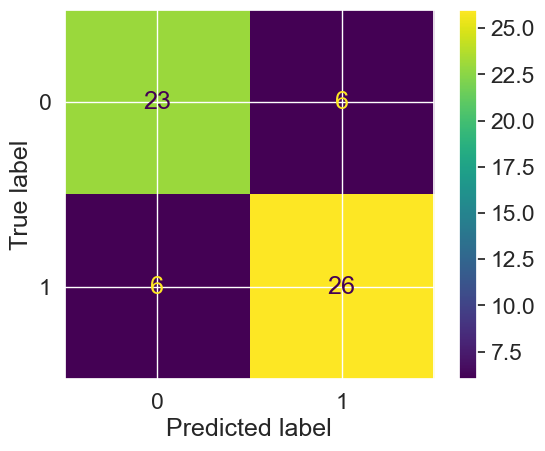

In [117]:
ConfusionMatrixDisplay.from_predictions(y_true=y_test,y_pred=y_preds)

**Classification Report**

In [118]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_preds))

              precision    recall  f1-score   support

           0       0.79      0.79      0.79        29
           1       0.81      0.81      0.81        32

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



In [119]:
 # Where presicion and recall become valuable

disease_true = np.zeros(10000)
disease_true[0] = 1 # only one positive case

disease_preds = np.zeros(10000) # model predicts every case as 0

pd.DataFrame(classification_report(disease_true,disease_preds, output_dict=True))

,0.0,1.0,accuracy,macro avg,weighted avg
precision,0.99990,0.0,0.9999,0.499950,0.99980
recall,1.00000,0.0,0.9999,0.500000,0.99990
f1-score,0.99995,0.0,0.9999,0.499975,0.99985
support,9999.00000,1.0,0.9999,10000.000000,10000.00000


To summarize classification metrics:

* **Accuracy** is a good measure to start with if all classes are balanced(e.g same amount of samples which are labelled with 0 or 1)
* **Precision** and **recall** become more important when classes are imballanced.
* If flase positive predictions are worse than false negative, aiim for higher precision
* If false negative predictions are worse than false negative, aim for higher recall.
* **F1-score** is a combination of precision and recall

### 4.2.2 Regression model evalutaion matrics

The ones we're going to cover are:
1. R^2 or coefficient of determination
2. Mean absolute error (MAE)
3. Mean squared error (MSE)

In [120]:
from sklearn.ensemble import RandomForestRegressor

np.random.seed(42)

X = housing_df.drop('target',axis =1)
y = housing_df['target']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

model = RandomForestRegressor()
model.fit(X_train,y_train)


RandomForestRegressor()

In [128]:
# Method 1: Calculate R² using the score method
r2_train_score = model.score(X_train, y_train)
r2_test_score = model.score(X_test, y_test)

# Method 2: Calculate R² using the r2_score function
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

# Display results
print(f"R² on training data: {r2_train_score:.4f}")
print(f"R² on test data (using model.score): {r2_test_score:.4f}")
print(f"R² on test data (using r2_score): {r2:.4f}")

R² on training data: 0.9737
R² on test data (using model.score): 0.8066
R² on test data (using r2_score): 0.8066


In [129]:
model.score(X_test,y_test)

0.8065734772187598

In [130]:
y_test.mean()

2.0550030959302323

In [131]:
from sklearn.metrics import r2_score

# Fill an array with y_test mean

y_test_mean = np.full(len(y_test), y_test.mean())

In [132]:
y_test_mean[:10]

array([2.0550031, 2.0550031, 2.0550031, 2.0550031, 2.0550031, 2.0550031,
       2.0550031, 2.0550031, 2.0550031, 2.0550031])

In [133]:
r2_score(y_true=y_test,y_pred=y_test_mean)

0.0

In [134]:
r2_score(y_true=y_test,y_pred=y_test)

1.0

**Mean absolute error (MAE)**

MAE is the average of the absolute differences between predictions and actual values.

It gives you an idea of how wrong your predictions are.

In [135]:
from sklearn.metrics import mean_absolute_error

y_preds = model.predict(X_test)
mae = mean_absolute_error(y_test,y_preds)
mae

0.32659871732073664

In [136]:
df = pd.DataFrame(data={"actual values": y_test,
                       "predicted values": y_preds})

df['differences'] = df['predicted values']-df['actual values']

In [137]:
df.head(10)

,actual values,predicted values,differences
20046,0.47700,0.493840,0.016840
3024,0.45800,0.754940,0.296940
15663,5.00001,4.928596,-0.071414
20484,2.18600,2.543160,0.357160
9814,2.78000,2.331760,-0.448240
13311,1.58700,1.652530,0.065530
7113,1.98200,2.343230,0.361230
7668,1.57500,1.661820,0.086820
18246,3.40000,2.474890,-0.925110
5723,4.46600,4.834478,0.368478


In [138]:
np.abs(df['differences']).mean()

0.32659871732073664

**Mean squared error (MSE)**

MSE is the mean of the square of the errors between actual and predicted values

In [139]:
# MSE
from sklearn.metrics import mean_squared_error

y_preds = model.predict(X_test)
mse = mean_squared_error(y_test,y_preds)
mse

0.2534678520824551

In [140]:
df['squared_differences'] = np.square(df['differences'])
df.head()

,actual values,predicted values,differences,squared_differences
20046,0.47700,0.493840,0.016840,0.000284
3024,0.45800,0.754940,0.296940,0.088173
15663,5.00001,4.928596,-0.071414,0.005100
20484,2.18600,2.543160,0.357160,0.127563
9814,2.78000,2.331760,-0.448240,0.200919


In [141]:
# Calculate MSE by hand

squared = np.square(df['differences'])
squared.mean()

0.2534678520824551

In [142]:
df_large_error = df.copy()
df_large_error.iloc[0]['squared_differences']=16

In [143]:
df_large_error

,actual values,predicted values,differences,squared_differences
20046,0.47700,0.493840,0.016840,16.000000
3024,0.45800,0.754940,0.296940,0.088173
15663,5.00001,4.928596,-0.071414,0.005100
20484,2.18600,2.543160,0.357160,0.127563
9814,2.78000,2.331760,-0.448240,0.200919
...,...,...,...,...
15362,2.63300,2.220380,-0.412620,0.170255
16623,2.66800,1.947760,-0.720240,0.518746
18086,5.00001,4.836378,-0.163632,0.026775
2144,0.72300,0.717820,-0.005180,0.000027


In [144]:
# Calculate MSE with large error
df_large_error['squared_differences'].mean()


0.2573437523766412

In [145]:
df_large_error.iloc[1:100]=20

In [146]:
df_large_error['squared_differences'].mean()

0.7334180712088106

### 4.2.3 Finally using the `scoring` parameter

In [147]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

np.random.seed(42)

X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

clf = RandomForestClassifier()

In [148]:
np.random.seed(42)

# Cross-validation accuracy
cv_acc = cross_val_score(clf,X,y,cv=5,scoring=None) # if scoring=None estimators default evaluation metric is used (Accuracy for classification model )

In [149]:
cv_acc

array([0.81967213, 0.90163934, 0.83606557, 0.78333333, 0.78333333])

In [150]:
# Cross vlaidated accuracy
print(f"The cross-validated accuracy is: {np.mean(cv_acc)*100:.2f}%")

The cross-validated accuracy is: 82.48%


In [151]:
np.random.seed(42)

cv_acc = cross_val_score(clf,X,y,cv=5,scoring="accuracy")
cv_acc

array([0.81967213, 0.90163934, 0.83606557, 0.78333333, 0.78333333])

In [152]:
# Cross vlaidated accuracy
print(f"The cross-validated accuracy is: {np.mean(cv_acc)*100:.2f}%")

The cross-validated accuracy is: 82.48%


In [153]:
np.random.seed(42)
cv_precision = cross_val_score(clf, X, y, cv=5, scoring='precision')
cv_precision

array([0.82352941, 0.93548387, 0.84848485, 0.79411765, 0.76315789])

In [154]:
# Cross vlaidated precision
print(f"The cross-validated precision is: {np.mean(cv_precision)}")

The cross-validated precision is: 0.8329547346025924


In [155]:
#Recall 
np.random.seed(42)
cv_recall = cross_val_score(clf,X,y,cv=5,scoring='recall')
cv_recall

array([0.84848485, 0.87878788, 0.84848485, 0.81818182, 0.87878788])

In [156]:
# Cross vlaidated recall
print(f"The cross-validated recall is: {np.mean(cv_recall)}")

The cross-validated recall is: 0.8545454545454545


Let's see the `scoring` parameter being using for a regression matric

In [157]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

np.random.seed(42)
X = housing_df.drop('target',axis =1)
y = housing_df['target']

model = RandomForestRegressor(n_estimators=100)

In [158]:
np.random.seed(42)
cv_r2 = cross_val_score(model,X,y,cv=3,scoring=None)
np.mean(cv_r2)

0.6545458023124507

In [159]:
cv_r2

array([0.62156985, 0.72075819, 0.62130937])

In [160]:
# Mean absolute error
cv_mae = cross_val_score(model,X,y,cv=5,scoring='neg_mean_absolute_error')
np.mean(cv_mae)

-0.4654168399709303

In [161]:
cv_mae

array([-0.54469613, -0.40814006, -0.43817161, -0.46276059, -0.47331582])

In [162]:
# Mean squared error
cv_mse = cross_val_score(model,X,y,cv=5,scoring='neg_mean_squared_error')
np.mean(cv_mse)

-0.43022014275796233

In [163]:
cv_mse

array([-0.52550379, -0.34795491, -0.3713332 , -0.4431212 , -0.46318762])

## 4.3 Using different evaluation metrics as Scikit-Learn functions

The 3rd way to evaluate sciket-learn machine learning models/estimators is to using `sklearn.metrics` module

In [164]:
from sklearn.metrics import accuracy_score, precision_score,recall_score,f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
np.random.seed(42)

X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

# split data
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

# Create model
clf = RandomForestClassifier()

#Fit the model
clf.fit(X_train,y_train)

# Make predictions
y_preds = clf.predict(X_test)

#EValuate model using evaluation functions
print("Classifier metrics on the test set")
print(f"Accuracy:{accuracy_score(y_test,y_preds)*100:.2f}%")
print(f"Precision:{precision_score(y_test,y_preds)}")
print(f"Recall:{recall_score(y_test,y_preds)}")
print(f"f1_score:{f1_score(y_test,y_preds)}")

Classifier metrics on the test set
Accuracy:85.25%
Precision:0.8484848484848485
Recall:0.875
f1_score:0.8615384615384616


In [165]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Create data 
X = housing_df.drop('target',axis=1)
y = housing_df['target']

# split data
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

# Create model
model = RandomForestRegressor()

#Fit the model
model.fit(X_train,y_train)

# Make predictions
y_preds = model.predict(X_test)

#EValuate model using evaluation functions
print("Classifier metrics on the test set")
print(f"r2_score:{r2_score(y_test,y_preds)*100:.2f}%")
print(f"MAE:{mean_absolute_error(y_test,y_preds)}")
print(f"MSE:{mean_squared_error(y_test,y_preds)}")

Classifier metrics on the test set
r2_score:80.95%
MAE:0.32678441937984515
MSE:0.25996890327609523


## 5. Improving a model

First predictions = baseline predictions.
First model = baseline model.

from a data perspective:
* Could we collect more data? (generally, the more data, the better)
* Could we improve our data?

From a model perspective:
* Is there a better model we could use?
* Could we improve the current model?

Parameters vs Hyperparameters
* Parameters = model find these patterns in data
* Hyperparameters = settings on a model you can adjust to (potentially) improve its ability to find patterns

Three ways to adjust hyperparameters:
  1. By Hand
  2. Randomly with RandomSearchCV
  3. Exhasutively with GridSearchCV

In [166]:
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier()

In [167]:
clf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

### 5.1 Tunning Hyperparameters by hand

Let's make 3 sets training, validation and test

In [168]:
clf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

We're going to try and adjust:
* `max_depth`
* `max_features`
* `min_sample_leaf`
* `min_sample_split`
* `n_estimators`

In [169]:
def evaluate_preds(y_true,y_preds):
    """
    Performs evaluation comparison on y_true labels vs. y_pred labels on a classification
    """
    accuracy = accuracy_score(y_true,y_preds)
    precision = precision_score(y_true,y_preds)
    recall = recall_score(y_true,y_preds)
    f1 = f1_score(y_true,y_preds)
    metric_dict = {"accuracy": round(accuracy,2),
                 "precision": round(precision,2),
                 "recall": round(recall,2),
                 "f1":round(f1,2)}
    print(f"Acc:{accuracy * 100:.2f}%")
    print(f"Precision:{precision:.2f}")
    print(f"Recall:{recall:.2f}")
    print(f"F1_score:{f1:.2f}")
    return metric_dict

In [170]:
from sklearn.ensemble import RandomForestClassifier

np.random.seed(42)

# shuffle the data
heart_disease_shuffled = heart_disease.sample(frac=1)

# split into X & y
X = heart_disease_shuffled.drop('target',axis=1)
y = heart_disease_shuffled['target']

# Split the data into train, validation & test sets

train_split = round(0.7 * len(heart_disease_shuffled)) # 70% of data
valid_split = round(train_split + 0.15 * len(heart_disease_shuffled)) # 15% of data
X_train,y_train = X[:train_split],y[:train_split]
X_valid,y_valid = X[train_split:valid_split],y[train_split:valid_split]
X_test,y_test = X[valid_split:],y[valid_split:]

# len(X_train), len(X_valid), len(X_test)

clf = RandomForestClassifier()
clf.fit(X_train,y_train)

# Make a baseline predictions
y_preds = clf.predict(X_valid)

# Evaluate the classifier on validation set
baseline_metrics = evaluate_preds(y_valid,y_preds)
baseline_metrics

Acc:82.22%
Precision:0.81
Recall:0.88
F1_score:0.85


{'accuracy': 0.82, 'precision': 0.81, 'recall': 0.88, 'f1': 0.85}

In [171]:
np.random.seed(42)

# create a seconf classifier with different hyperparameters
clf_2  = RandomForestClassifier(n_estimators=100)
clf_2.fit(X_train,y_train)

# make predictions
y_preds_2= clf_2.predict(X_valid)

# Evaluate the 2nd classifier
clf_2_metrics = evaluate_preds(y_valid,y_preds_2)

Acc:82.22%
Precision:0.84
Recall:0.84
F1_score:0.84


In [172]:
clf_3 = RandomForestClassifier(n_estimators=100,max_depth=10)

### 5.2 Hyperparaemter tuning with RandomizedSearchCV

In [176]:
from sklearn.model_selection import RandomizedSearchCV

grid = {"n_estimators":[10,100,200,500,1000,1200],
       "max_depth":[None,5,10,20,30],
       "max_features":["auto","sqrt"],
       "min_samples_split":[2,4,6],
       "min_samples_leaf":[1,2,4]}

np.random.seed(42)

# split into X & y
X = heart_disease_shuffled.drop("target",axis=1)
y = heart_disease_shuffled["target"]

# Split into train and test sets
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

# Instantiate RandomForestClassifier
clf = RandomForestClassifier(n_jobs=1)

#setup RadomizedSearchCV
rs_clf = RandomizedSearchCV(estimator=clf,
                           param_distributions=grid,
                           n_iter=10, # number of models to try
                           cv =5,
                           verbose=2)

# Fit the RandomizedSearchCV version of clf
rs_clf.fit(X_train,y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END max_depth=5, max_features=sqrt, min_samples_leaf=2, min_samples_split=6, n_estimators=1200; total time=   2.6s
[CV] END max_depth=5, max_features=sqrt, min_samples_leaf=2, min_samples_split=6, n_estimators=1200; total time=   2.5s
[CV] END max_depth=5, max_features=sqrt, min_samples_leaf=2, min_samples_split=6, n_estimators=1200; total time=   2.4s
[CV] END max_depth=5, max_features=sqrt, min_samples_leaf=2, min_samples_split=6, n_estimators=1200; total time=   2.9s
[CV] END max_depth=5, max_features=sqrt, min_samples_leaf=2, min_samples_split=6, n_estimators=1200; total time=   3.1s
[CV] END max_depth=30, max_features=auto, min_samples_leaf=2, min_samples_split=4, n_estimators=100; total time=   0.0s
[CV] END max_depth=30, max_features=auto, min_samples_leaf=2, min_samples_split=4, n_estimators=100; total time=   0.0s
[CV] END max_depth=30, max_features=auto, min_samples_leaf=2, min_samples_split=4, n_estimators=100

RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=1),
                   param_distributions={'max_depth': [None, 5, 10, 20, 30],
                                        'max_features': ['auto', 'sqrt'],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 4, 6],
                                        'n_estimators': [10, 100, 200, 500,
                                                         1000, 1200]},
                   verbose=2)

In [177]:
rs_clf.best_params_

{'n_estimators': 200,
 'min_samples_split': 6,
 'min_samples_leaf': 2,
 'max_features': 'sqrt',
 'max_depth': None}

In [178]:
# make predictions with the best hyperparameters
rs_y_preds = rs_clf.predict(X_test)

# Evalaute the predictions
rs_metrics = evaluate_preds(y_test,rs_y_preds)

Acc:81.97%
Precision:0.77
Recall:0.86
F1_score:0.81


### 5.3 Hyperparameters tunning with GridSearchCV

In [179]:
grid

{'n_estimators': [10, 100, 200, 500, 1000, 1200],
 'max_depth': [None, 5, 10, 20, 30],
 'max_features': ['auto', 'sqrt'],
 'min_samples_split': [2, 4, 6],
 'min_samples_leaf': [1, 2, 4]}

In [180]:
grid_2 = {"n_estimators":[100,200,500],
       "max_depth":[None],
       "max_features":["auto","sqrt"],
       "min_samples_split":[6],
       "min_samples_leaf":[1,2]}

In [181]:
from sklearn.model_selection import GridSearchCV

np.random.seed(42)

# split into X & y
X = heart_disease_shuffled.drop("target",axis=1)
y = heart_disease_shuffled["target"]

# Split into train and test sets
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

# Instantiate RandomForestClassifier
clf = RandomForestClassifier(n_jobs=1)

#setup GridSearchCV
gs_clf = GridSearchCV(estimator=clf,
                           param_grid=grid_2,
                           cv =5,
                           verbose=2)

# Fit the GridSearchCV version of clf
gs_clf.fit(X_train,y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=6, n_estimators=100; total time=   0.0s
[CV] END max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=6, n_estimators=100; total time=   0.0s
[CV] END max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=6, n_estimators=100; total time=   0.0s
[CV] END max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=6, n_estimators=100; total time=   0.0s
[CV] END max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=6, n_estimators=100; total time=   0.0s
[CV] END max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=6, n_estimators=200; total time=   0.0s
[CV] END max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=6, n_estimators=200; total time=   0.0s
[CV] END max_depth=None, max_features=auto, min_samples_leaf=1, min_samples_split=6, 

GridSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=1),
             param_grid={'max_depth': [None], 'max_features': ['auto', 'sqrt'],
                         'min_samples_leaf': [1, 2], 'min_samples_split': [6],
                         'n_estimators': [100, 200, 500]},
             verbose=2)

In [182]:
gs_clf.best_params_

{'max_depth': None,
 'max_features': 'sqrt',
 'min_samples_leaf': 1,
 'min_samples_split': 6,
 'n_estimators': 100}

In [183]:
gs_y_preds = gs_clf.predict(X_test)

gs_metrics = evaluate_preds(y_test,gs_y_preds)

Acc:81.97%
Precision:0.77
Recall:0.86
F1_score:0.81


lets comapre our different models matrices

<Axes: >

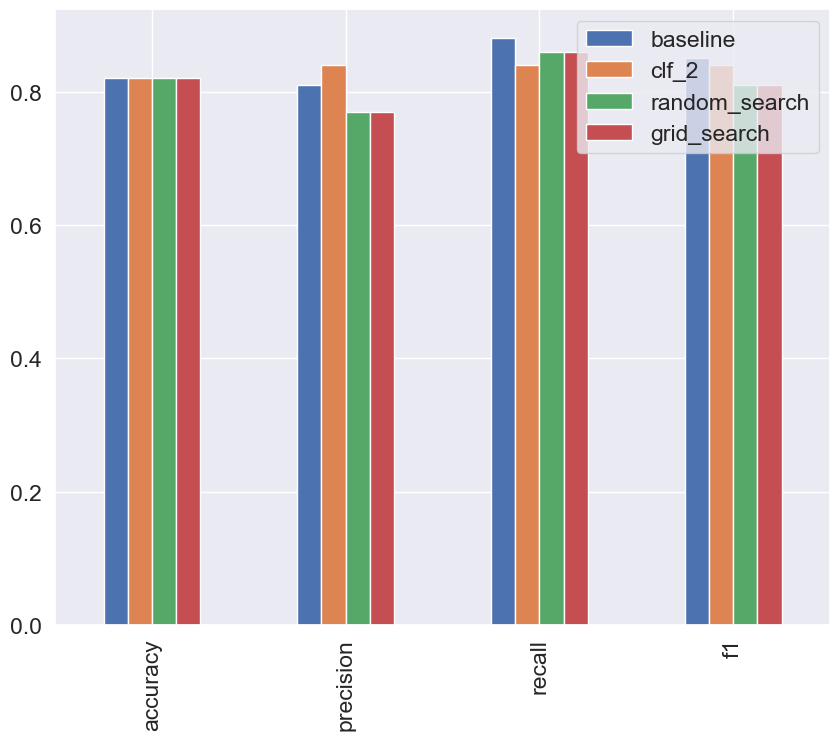

In [185]:
compare_metrices = pd.DataFrame({"baseline": baseline_metrics,
                                "clf_2":clf_2_metrics,
                                "random_search": rs_metrics,
                                "grid_search":gs_metrics})

compare_metrices.plot.bar(figsize=(10,8))

## 6. Saving and loading our trained Machine learning models

Two wasys to save and load the model
1. with python `pickle` module
2. with the `joblib` module

**Pickle**

In [186]:
import pickle

pickle.dump(gs_clf, open("gs_random_forrest_model_1.pkl", "wb"))

In [189]:
# Load a saved model

load_pickle_model = pickle.load(open("gs_random_forrest_model_1.pkl",'rb'))

In [190]:
# Make some prediction
pickle_y_preds = load_pickle_model.predict(X_test)

evaluate_preds(y_test,pickle_y_preds)


Acc:81.97%
Precision:0.77
Recall:0.86
F1_score:0.81


{'accuracy': 0.82, 'precision': 0.77, 'recall': 0.86, 'f1': 0.81}

**Joblib**

In [191]:
from joblib import load, dump

dump(gs_clf,filename="gs_random_forrest_model_1.joblib")

['gs_random_forrest_model_1.joblib']

In [192]:
# Import a saved joblib model
loaded_joblib_model = load(filename="gs_random_forrest_model_1.joblib")

In [193]:
# Make & evalaute joblic predictions
joblib_y_preds = loaded_joblib_model.predict(X_test)
evaluate_preds(y_test, joblib_y_preds)

Acc:81.97%
Precision:0.77
Recall:0.86
F1_score:0.81


{'accuracy': 0.82, 'precision': 0.77, 'recall': 0.86, 'f1': 0.81}

## 7. Putting it all together!

In [379]:
data = pd.read_csv("car-sales-extended-missing-data.csv")

In [380]:
data

,Make,Colour,Odometer (KM),Doors,Price
0,Honda,White,35431.0,4.0,15323.0
1,BMW,Blue,192714.0,5.0,19943.0
2,Honda,White,84714.0,4.0,28343.0
3,Toyota,White,154365.0,4.0,13434.0
4,Nissan,Blue,181577.0,3.0,14043.0
...,...,...,...,...,...
995,Toyota,Black,35820.0,4.0,32042.0
996,NaN,White,155144.0,3.0,5716.0
997,Nissan,Blue,66604.0,4.0,31570.0
998,Honda,White,215883.0,4.0,4001.0


In [386]:
data.dtypes

Make              object
Colour            object
Odometer (KM)    float64
Doors            float64
Price            float64
dtype: object

In [387]:
data.isna().sum()

Make             49
Colour           50
Odometer (KM)    50
Doors            50
Price            50
dtype: int64



Steps we want to do (all in one cell):

1. Fill missing data
2. Convert data to numbers
3. Build a model on the data

In [392]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Modelling
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV

# setup random seed
import numpy as np
np.random.seed(42)

# import data and drop rows with missing labels
data = pd.read_csv("car-sales-extended-missing-data.csv")
data.dropna(subset=["Price"],inplace=True)

# Define different features and transformer pipeline
categorical_features = ["Make","Colour"]
categorical_transformer = Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="constant", fill_value='missing')),
    ("onehot", OneHotEncoder(handle_unknown='ignore'))])
door_feature = ["Doors"]
door_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy='constant', fill_value=4))
])

numeric_features = ['Odometer (KM)']
numeric_transformer = Pipeline(steps=[
    ("imputer",SimpleImputer(strategy='mean'))
])

# setup preprocessing steps  (fill missing values, then convert to numbers)
preprocessor = ColumnTransformer(transformers=[
    ("cat", categorical_transformer, categorical_features),
    ("door", door_transformer, door_feature),
    ("num", numeric_transformer, numeric_features)
])

# Creating a preprocessing and modelling pipeline
model = Pipeline(steps=[("preprocessor", preprocessor),
                       ("model", RandomForestRegressor())])

# split data
X = data.drop("Price", axis=1)
y = data["Price"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

# fit & score the model
model.fit(X_train,y_train)
model.score(X_test,y_test)

0.22188417408787875

**It's also possible to use `GridSearchCV` or `RandomizedSearchCV` with our `Pipeline`**

In [395]:
# Use gridSearchCV with our regression Pipeline
pipe_grid = {
    "preprocessor__num__imputer__strategy":['mean','median'],
    "model__n_estimators":[100,1000],
    "model__max_depth":[None,5],
    "model__max_features":["sqrt"],
    "model__min_samples_split":[2,4]
}

gs_model = GridSearchCV(model, pipe_grid,cv=5, verbose=2)
gs_model.fit(X_train,y_train)


Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END model__max_depth=None, model__max_features=sqrt, model__min_samples_split=2, model__n_estimators=100, preprocessor__num__imputer__strategy=mean; total time=   0.3s
[CV] END model__max_depth=None, model__max_features=sqrt, model__min_samples_split=2, model__n_estimators=100, preprocessor__num__imputer__strategy=mean; total time=   0.3s
[CV] END model__max_depth=None, model__max_features=sqrt, model__min_samples_split=2, model__n_estimators=100, preprocessor__num__imputer__strategy=mean; total time=   0.3s
[CV] END model__max_depth=None, model__max_features=sqrt, model__min_samples_split=2, model__n_estimators=100, preprocessor__num__imputer__strategy=mean; total time=   0.3s
[CV] END model__max_depth=None, model__max_features=sqrt, model__min_samples_split=2, model__n_estimators=100, preprocessor__num__imputer__strategy=mean; total time=   0.3s
[CV] END model__max_depth=None, model__max_features=sqrt, model__min_sampl

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(fill_value='missing',
                                                                                                        strategy='constant')),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Make',
                                                                          'Colour']),
                                                                        ('door',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(fill_value=4,
                                                                                                        strategy='constant'))]),
                                                                         ['Doors']),
                                                                        ('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer())]),
                                                                         ['Odometer '
                                                                          '(KM)'])])),
                                       ('model', RandomForestRegressor())]),
             param_grid={'model__max_depth': [None, 5],
                         'model__max_features': ['sqrt'],
                         'model__min_samples_split': [2, 4],
                         'model__n_estimators': [100, 1000],
                         'preprocessor__num__imputer__strategy': ['mean',
                                                                  'median']},
             verbose=2)

In [396]:
gs_model.score(X_test,y_test)

0.2848784564026805

In [397]:
what_were_covering

['0. An end-to-end Scikit-Learn workflow',
 '1. Getting the data ready',
 '2. Choose the right estimator/algorithm for our problems',
 '3. Fit the model/algorithm and use it to make predictions on our data',
 '4. Evaluation a model',
 '5. Improve a model',
 '6. Save and load a trained model',
 '7. Putting it all together!']